# 03. Frozen Evaluation Results and Audit Analysis

## Purpose
This notebook provides an analytical breakdown of the ACPDAD frozen final test evaluation. It examines:
- Prediction coverage and observation delivery gaps.
- Conditional vs end-to-end Evil_Twin recall and precision.
- Performance shifts across changed environmental and adversarial test conditions.
- Benign false alert rates, episode durations, and physics residual interactions.
- Cyber-physical limitations in detecting network Denial of Service (DoS).

> **Frozen Evaluation Governance Notice**  
> - All evidence analyzed in this notebook is **strictly read-only**, loaded directly from frozen evaluation artifacts in `results/frozen_test/analysis/`.
> - The frozen test was executed **once** after finalizing protocol locks (`pre_generation_lock.json`, `pre_score_manifest.json`).
> - **No retraining, tuning, re-inferring, or rescoring is performed**.
> - Results represent **simulated synthetic research only**. They do not constitute validation on physical aircraft, live radio links, captured Wi-Fi, or ArduPilot SITL.

In [1]:
import os
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd() if (Path.cwd() / 'results').exists() else Path.cwd().parent
os.chdir(ROOT)

FROZEN_DIR = Path('results/frozen_test/analysis')

# Load high-level frozen test metrics
with open(FROZEN_DIR / 'metrics.json') as f:
    metrics = json.load(f)

per_cond = pd.read_csv(FROZEN_DIR / 'per_condition_metrics.csv')

print("Evaluation Status: Frozen Simulated Evaluation (Protocol Locked)")
print(f"Provenance: {metrics['provenance']}")
print(f"Scheduled Timeline Observations: {metrics['scheduled_observations']:,}")
print(f"Timely Delivered Predictions: {metrics['timely_predictions']:,}")
print(f"Overall Prediction Coverage: {metrics['prediction_coverage'] * 100:.2f}%")
print(f"Conditional Evil_Twin Recall (Scored Rows): {metrics['conditional_evil_twin_recall'] * 100:.2f}%")
print(f"End-to-End Evil_Twin Recall (Scheduled Rows): {metrics['end_to_end_evil_twin_recall'] * 100:.2f}%")
print(f"Evil_Twin Precision: {metrics['evil_twin_precision'] * 100:.2f}%")
print(f"Benign Missions with Alert: {metrics['benign_missions_with_alert']}/{metrics['benign_mission_count']} ({metrics['benign_mission_alert_rate']*100:.1f}%)")

Evaluation Status: Frozen Simulated Evaluation (Protocol Locked)
Provenance: SIMULATED_ONLY_NOT_SITL_NOT_CAPTURED
Scheduled Timeline Observations: 150,000
Timely Delivered Predictions: 138,814
Overall Prediction Coverage: 92.54%
Conditional Evil_Twin Recall (Scored Rows): 98.75%
End-to-End Evil_Twin Recall (Scheduled Rows): 84.76%
Evil_Twin Precision: 98.09%
Benign Missions with Alert: 36/100 (36.0%)

## Scored-Row vs End-to-End Observation Accounting
In cyber-physical telemetry systems, network loss, buffer drops, or excessive latency prevent some observations from reaching the detector before the 0.5s deadline.
- **Conditional / Scored-Row Metrics**: Evaluated *only* on timely observations that actually reached the detector.
- **End-to-End Metrics**: Evaluated across *all scheduled mission timeline samples*, counting dropped/late frames as `UNAVAILABLE` misses.

Evaluating only scored rows produces an inflated picture of security. In ACPDAD, every single scheduled observation is rigorously accounted for.

In [2]:
with open(FROZEN_DIR / 'gap_breakdown.csv') as f:
    gap_df = pd.read_csv(f)

print("Observation Accounting Breakdown:")
print(gap_df.to_string(index=False))

total_sched = metrics['scheduled_observations']
timely_pred = metrics['timely_predictions']
gap_count = metrics['gap_breakdown']['packet_never_delivered_network_loss']

print(f"\nScheduled ({total_sched:,}) = Timely ({timely_pred:,}) + Gaps ({gap_count:,})")
print(f"Exact Accounting Reconciliation: {metrics['gap_breakdown_reconciles']}")

# Compare Scored vs End-to-End Confusion Matrices
cm_scored = pd.read_csv(FROZEN_DIR / 'confusion_matrix_scored.csv', index_col=0)
cm_e2e = pd.read_csv(FROZEN_DIR / 'confusion_matrix_end_to_end.csv', index_col=0)

print("\n--- Scored-Row Confusion Matrix (Excludes Drops) ---")
print(cm_scored)
print("\n--- End-to-End Confusion Matrix (Includes UNAVAILABLE Gaps) ---")
print(cm_e2e)

Observation Accounting Breakdown:
                       condition                              reason  count
           mission_initial_state packet_never_delivered_network_loss   1821
         wind_background_traffic packet_never_delivered_network_loss   2735
attack_timing_duration_intensity packet_never_delivered_network_loss   1906
     replay_delay_source_segment packet_never_delivered_network_loss   2719
        unseen_ap_benign_roaming packet_never_delivered_network_loss   2005

Scheduled (150,000) = Timely (138,814) + Gaps (11,186)
Exact Accounting Reconciliation: True

--- Scored-Row Confusion Matrix (Excludes Drops) ---
           Benign   DoS  Replay  Evil_Twin    FDI
Benign      89117  2619     159        169    172
DoS          7106  4886       0         23      4
Replay        564    15   11656          2      0
Evil_Twin     129     6       0      10645      0
FDI          1164     0       0         13  10365

--- End-to-End Confusion Matrix (Includes UNAVAILABLE Gaps) -

## Visualizing Scored vs End-to-End Confusion Matrices
The visual difference between the two matrices demonstrates the real-world impact of network loss:

<string>:34: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown

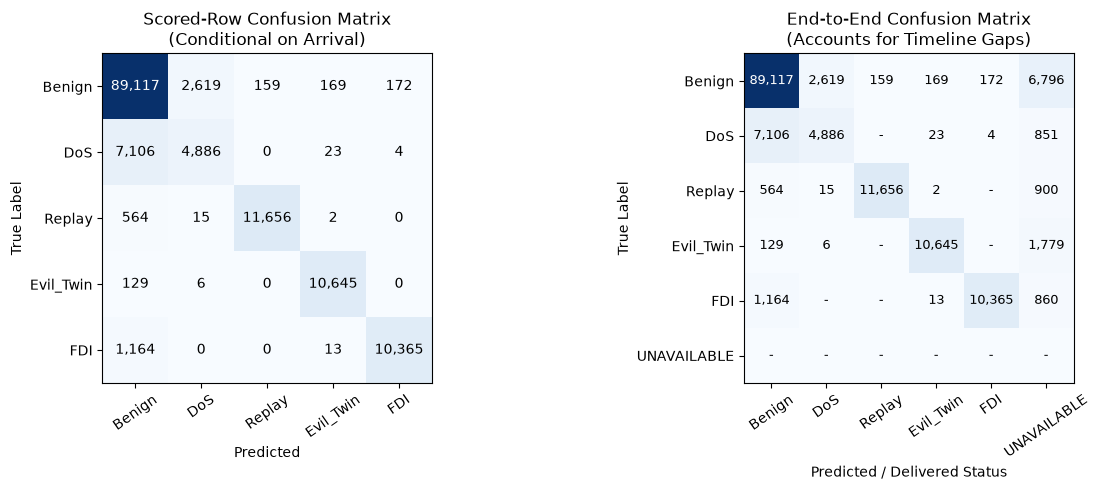

In [3]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

classes = ['Benign', 'DoS', 'Replay', 'Evil_Twin', 'FDI']

im1 = ax1.imshow(cm_scored.values, cmap='Blues')
ax1.set_title('Scored-Row Confusion Matrix\n(Conditional on Arrival)')
ax1.set_xticks(range(len(classes)))
ax1.set_xticklabels(classes, rotation=35)
ax1.set_yticks(range(len(classes)))
ax1.set_yticklabels(classes)
ax1.set_xlabel('Predicted')
ax1.set_ylabel('True Label')
for i in range(len(classes)):
    for j in range(len(classes)):
        ax1.text(j, i, f"{cm_scored.values[i, j]:,}", ha='center', va='center',
                 color='white' if cm_scored.values[i, j] > cm_scored.values.max()/2 else 'black')

all_classes = classes + ['UNAVAILABLE']
im2 = ax2.imshow(cm_e2e.values, cmap='Blues')
ax2.set_title('End-to-End Confusion Matrix\n(Accounts for Timeline Gaps)')
ax2.set_xticks(range(len(all_classes)))
ax2.set_xticklabels(all_classes, rotation=35)
ax2.set_yticks(range(len(all_classes)))
ax2.set_yticklabels(all_classes)
ax2.set_xlabel('Predicted / Delivered Status')
ax2.set_ylabel('True Label')
for i in range(len(all_classes)):
    for j in range(len(all_classes)):
        val = cm_e2e.values[i, j]
        ax2.text(j, i, f"{val:,}" if val > 0 else "-", ha='center', va='center',
                 color='white' if val > cm_e2e.values.max()/2 else 'black', fontsize=9)

plt.tight_layout()
plt.show()

## Performance Across Changed Environmental and Adversarial Conditions
The frozen evaluation tested five prespecified conditions to measure robustness against distribution shift:
1. **`mission_initial_state`**: Baseline variation in initial position, altitude, and heading.
2. **`wind_background_traffic`**: Severe turbulent wind gusts and competing background network packets.
3. **`attack_timing_duration_intensity`**: Short attack bursts, low tampering intensity, varied attack timing.
4. **`replay_delay_source_segment`**: Extended replay delays (1s to 5s) and varied injection durations.
5. **`unseen_ap_benign_roaming`**: Flight paths traversing previously unseen BSSIDs and AP handoffs.

In [4]:
cols_to_show = ['condition', 'prediction_coverage', 'conditional_evil_twin_recall', 
                    'end_to_end_evil_twin_recall', 'evil_twin_precision', 'benign_alert_mission_rate', 
                    'false_alert_episodes_per_benign_minute']

summary_table = per_cond[cols_to_show].copy()
summary_table['prediction_coverage'] = (summary_table['prediction_coverage'] * 100).round(1).astype(str) + '%'
summary_table['conditional_evil_twin_recall'] = (summary_table['conditional_evil_twin_recall'] * 100).round(1).astype(str) + '%'
summary_table['end_to_end_evil_twin_recall'] = (summary_table['end_to_end_evil_twin_recall'] * 100).round(1).astype(str) + '%'
summary_table['evil_twin_precision'] = (summary_table['evil_twin_precision'] * 100).round(1).astype(str) + '%'
summary_table['benign_alert_mission_rate'] = (summary_table['benign_alert_mission_rate'] * 100).round(1).astype(str) + '%'
summary_table['false_alert_episodes_per_benign_minute'] = summary_table['false_alert_episodes_per_benign_minute'].round(2)

print("Per-Condition Performance Metrics Table:")
print(summary_table.to_string(index=False))

Per-Condition Performance Metrics Table:
                       condition prediction_coverage conditional_evil_twin_recall end_to_end_evil_twin_recall evil_twin_precision benign_alert_mission_rate  false_alert_episodes_per_benign_minute
           mission_initial_state               93.9%                        99.0%                       87.3%               99.7%                     30.0%                                    0.70
         wind_background_traffic               90.9%                        98.2%                       82.1%               98.7%                     65.0%                                    1.20
attack_timing_duration_intensity               93.6%                        98.5%                       87.0%               99.5%                     25.0%                                    0.60
     replay_delay_source_segment               90.9%                        99.0%                       82.1%               99.0%                     40.0%                    

## Visualizing Condition Robustness: Coverage, Recall, and Precision

<string>:19: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown

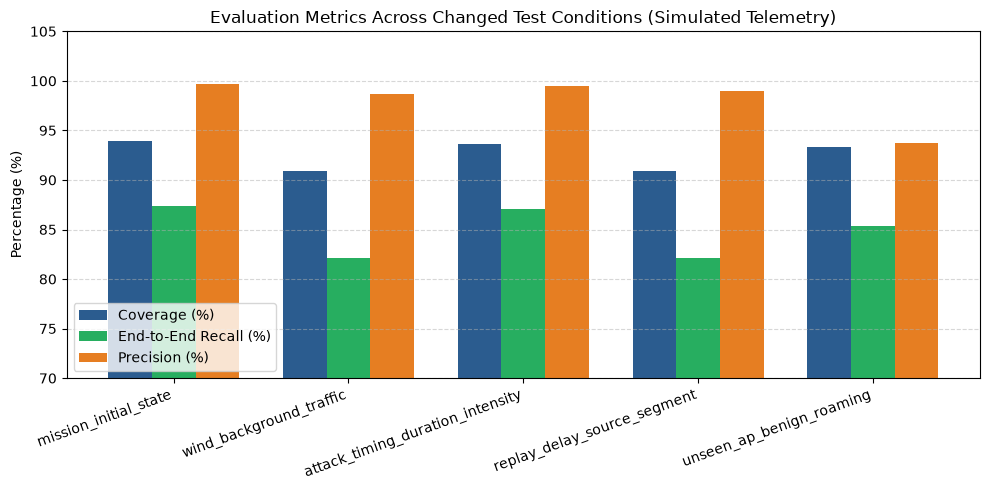

In [5]:
fig, ax = plt.subplots(figsize=(10, 5))

x = np.arange(len(per_cond))
width = 0.25

rects1 = ax.bar(x - width, per_cond['prediction_coverage'] * 100, width, label='Coverage (%)', color='#2b5c8f')
rects2 = ax.bar(x, per_cond['end_to_end_evil_twin_recall'] * 100, width, label='End-to-End Recall (%)', color='#27ae60')
rects3 = ax.bar(x + width, per_cond['evil_twin_precision'] * 100, width, label='Precision (%)', color='#e67e22')

ax.set_ylabel('Percentage (%)')
ax.set_title('Evaluation Metrics Across Changed Test Conditions (Simulated Telemetry)')
ax.set_xticks(x)
ax.set_xticklabels(per_cond['condition'], rotation=20, ha='right')
ax.set_ylim(70, 105)
ax.grid(axis='y', linestyle='--', alpha=0.5)
ax.legend(loc='lower left')

plt.tight_layout()
plt.show()

## Cyber-Physical Limitations & Vulnerability Analysis

### 1. Unseen AP Roaming and Precision Degradation
Under `unseen_ap_benign_roaming`, Evil_Twin precision drops to **93.75%** (compared to >99% in other conditions). When legitimate roaming occurs across previously unseen AP identities, the sudden handoff delay and BSSID change closely resemble rogue AP injection, triggering false alarms.

### 2. The DoS Cyber-Physical Dilemma
In `confusion_matrix_end_to_end.csv`, DoS exhibits an end-to-end recall of only **37.96%** (scored recall: 40.65%).
- **Why?** Denial of Service works by dropping packets. When packets are dropped, no telemetry arrives at the detector.
- When an occasional packet *does* make it through the jammed channel, its kinematic payload (e.g., hovering altitude and position) is physically normal. The ML model examines the delivered payload and correctly identifies nominal kinematics as `Benign`.
- **Takeaway**: DoS cannot be effectively mitigated by payload classifiers alone; it requires an integrated network health monitor that treats packet silence as a distinct system warning.

End-to-End Recall by Class:
  - Benign: 89.99%
  - DoS: 37.96%
  - Evil_Twin: 84.76%
  - FDI: 83.58%
  - Replay: 88.73%

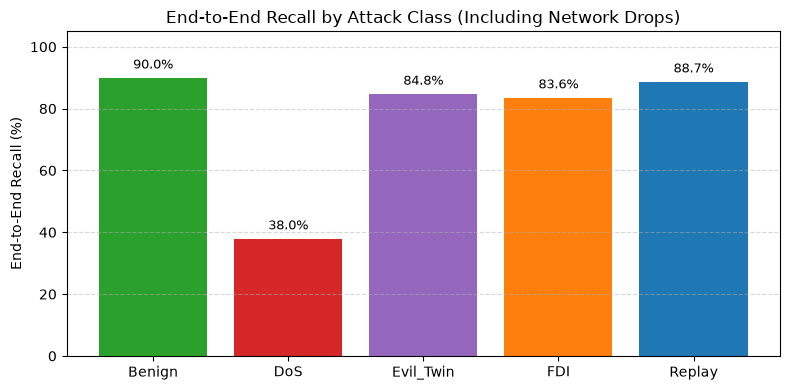

In [6]:
e2e_recalls = metrics['end_to_end_per_class_recall']
print("End-to-End Recall by Class:")
for cls, r in e2e_recalls.items():
    print(f"  - {cls}: {r*100:.2f}%")

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(e2e_recalls.keys(), [v * 100 for v in e2e_recalls.values()], 
              color=['#2ca02c', '#d62728', '#9467bd', '#ff7f0e', '#1f77b4'])
ax.set_ylabel('End-to-End Recall (%)')
ax.set_title('End-to-End Recall by Attack Class (Including Network Drops)')
ax.set_ylim(0, 105)
ax.grid(axis='y', linestyle='--', alpha=0.5)

for bar in bars:
    yval = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2.0, yval + 2, f"{yval:.1f}%", ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()

## Benign False Alert Rates and Physics Warnings
- Across the 100 benign test missions, **36% had at least one false alert episode**, producing **0.79 false alert episodes per benign minute**.
- Turbulence in `wind_background_traffic` caused the highest false alert rate (65% of benign missions, 1.2 episodes/min).
- The independent physical residual warning system logged 407 episodes without contaminating ML alert decisions, proving the benefit of separating kinematic plausibility checks from statistical classification.

Total Alert Episodes Logged: 844
False Alert Episodes: 189
Mean False Alert Episode Duration: 3.66s
<string>:15: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown

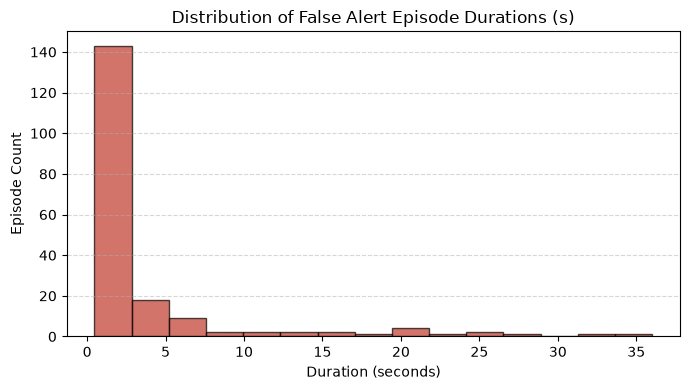

In [7]:
episodes_df = pd.read_csv(FROZEN_DIR / 'attack_alert_episodes.csv')
false_episodes = episodes_df[episodes_df['false_alert'] == True]

print(f"Total Alert Episodes Logged: {len(episodes_df)}")
print(f"False Alert Episodes: {len(false_episodes)}")
print(f"Mean False Alert Episode Duration: {metrics['mean_false_alert_episode_duration_s']:.2f}s")

fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(false_episodes['duration_s'], bins=15, color='#c0392b', edgecolor='black', alpha=0.7)
ax.set_title('Distribution of False Alert Episode Durations (s)')
ax.set_xlabel('Duration (seconds)')
ax.set_ylabel('Episode Count')
ax.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

## Conclusion & Methodological Insights
1. **The Scored-Only Trap**: Reporting only scored-row recall (98.75% for Evil_Twin) hides the operational reality that ~15% of attacks are lost due to channel drops (end-to-end recall: 84.76%). Rigorous accounting for unavailable samples is vital for real-world cyber-physical defense.
2. **Channel vs Payload Specialization**: Classifiers excel at detecting payload manipulation (FDI, Replay) and subtle metadata shifts (Evil_Twin), but network silence (DoS) must be handled by transport-level health monitors.
3. **Simulated Research Boundary**: These findings represent controlled synthetic benchmarks. Transfer to SITL or physical aircraft requires dedicated empirical calibration of RF channel noise and flight dynamics.